# 004 — VAE: Exploración de un espacio latente a partir de espectrogramas

Este experimento continúa la progresión iniciada en los notebooks anteriores:

```text
001_latent_sound_space_keyboard
        ↓
002_autoencoder_latent_sound_space
        ↓
003_VAE_latent_sound_generation
        ↓
004_VAE_audio_spectrogram_latent_exploration
```
 ¿Qué cambia en este experimento?

En los primeros experimentos trabajamos directamente con señales de audio.

Aquí cambiamos la representación del sonido:

```text
Audio
  ↓
Espectrograma
  ↓
VAE
  ↓
Espacio latente aprendido
  ↓
Exploración del espacio
  ↓
Nuevo espectrograma
  ↓
Audio
```

El **espectrograma** permite representar el sonido como una combinación de:

* **tiempo** → cuándo ocurre cada evento sonoro
* **frecuencia** → qué frecuencias están presentes
* **amplitud** → con qué intensidad aparecen

De esta manera, el VAE no trabaja solamente con una onda de audio, sino con una representación de sus características temporales y espectrales.

## Objetivo

El objetivo es observar si el VAE puede aprender una organización interna de estas características y construir un **espacio latente sonoro** que pueda ser explorado.

Por ejemplo:

```text
sonido A ──┐
           ├──→ VAE → espacio latente
sonido B ──┘
```

Una vez aprendido este espacio, podemos desplazarnos dentro de él y generar nuevas representaciones sonoras.

## Cambio conceptual

Este notebook representa un paso desde:

> **"generar una señal"**

hacia:

> **"explorar una organización latente de características sonoras"**

El interés ya no está solamente en producir un sonido, sino en estudiar **cómo diferentes sonidos pueden organizarse y relacionarse dentro de un espacio aprendido por la máquina**.


Diferencia respecto al experimento 003

En el experimento 003, el VAE trabaja directamente con la señal de audio:

Audio
  ↓
onda de audio
  ↓
[0.01, 0.02, 0.03, ...]
  ↓
VAE

En este experimento 004, transformamos primero el audio en un espectrograma:

Audio
  ↓
Espectrograma
  ↓
tiempo + frecuencia
  ↓
VAE

La diferencia principal es, por tanto, la representación que recibe el VAE.

003: el VAE aprende a partir de la forma de la onda.
004: el VAE aprende a partir de una representación tiempo–frecuencia del sonido.

Esto permite estudiar si el espacio latente puede organizar características sonoras más complejas, como la distribución de frecuencias a lo largo del tiempo.

el espacio latente es algo q se crea en paralelo al VAE?
El espacio latente no es algo que se crea en paralelo al VAE como un objeto separado.

El VAE aprende una representación latente como parte de su propia arquitectura.

Puedes imaginarlo así:

                 VAE
                  │
Audio /            │
Espectrograma ──→ Encoder
                  │
                  ↓
          ESPACIO LATENTE
             (z1, z2, ...)
                  │
                  ↓
               Decoder
                  │
                  ↓
        Espectrograma reconstruido
¿Qué ocurre durante el entrenamiento?

El encoder recibe el espectrograma y lo comprime.

In [8]:

# ==========================================================
# CELDA 1 — INSTALAR LIBRERÍAS
# ==========================================================

!pip install librosa tensorflow

# librosa:
# Permite trabajar con audio.
# La utilizaremos para cargar los archivos .wav
# y transformarlos en espectrogramas.

# tensorflow:
# Permite construir y entrenar el VAE.
# Aquí la red neuronal aprenderá una representación
# latente de las características sonoras.



CELDA 2 — Importar librerías


In [9]:

# ==========================================================
# CELDA 2 — IMPORTAR LIBRERÍAS
# ==========================================================

# NumPy:
# Permite trabajar con los datos numéricos del audio,
# espectrogramas y vectores.
import numpy as np


# Matplotlib:
# Permite visualizar los datos y representar
# los espectrogramas como imágenes.
import matplotlib.pyplot as plt


# Librosa:
# Librería especializada en análisis de audio.
# La utilizaremos para cargar sonidos y calcular
# espectrogramas.
import librosa
import librosa.display


# TensorFlow:
# Framework de aprendizaje automático.
# Aquí lo utilizaremos para construir y entrenar
# el VAE.
import tensorflow as tf


# Keras:
# Herramientas de TensorFlow para construir
# las diferentes capas de la red neuronal.
from tensorflow.keras import layers, Model


# IPython:
# Permite reproducir el audio directamente dentro
# del notebook.
from IPython.display import Audio, display



```

### En resumen

```text
NumPy        → datos numéricos
Matplotlib   → visualización
Librosa      → análisis de audio
TensorFlow   → aprendizaje automático
Keras        → construcción del VAE
IPython      → reproducción del audio
```

El flujo que estamos preparando es:

```text
.wav
 ↓
Librosa
 ↓
Espectrograma
 ↓
NumPy
 ↓
VAE (TensorFlow / Keras)
 ↓
Espacio latente
 ↓
Espectrograma generado
 ↓
Audio
```

CELDA 3 — Crear dataset de sonidos

Primero necesito sonidos.

Usaré sonidos sintéticos variados:

diferentes frecuencias
armónicos
ruido

### ¿Qué estamos creando aquí?

El notebook todavía **no está entrenando el VAE**.

Primero estamos construyendo los datos que el VAE tendrá que aprender:

```text
frecuencia fundamental
        +
    armónico
        +
      ruido
        ↓
     sonido
        ↓
    dataset
```

Tengo:

```text
100 Hz → diferentes armónicos
150 Hz → diferentes armónicos
200 Hz → diferentes armónicos
...
950 Hz → diferentes armónicos
```

Por eso esta celda es importante conceptualmente:

> **Antes de aprender un espacio latente, necesito crear el conjunto de sonidos que ocupará ese espacio.**


In [10]:

# ==========================================================
# CELDA 3 — CREAR DATASET DE SONIDOS
# ==========================================================

# Frecuencia de muestreo:
# 22.050 muestras por segundo.
# Es una frecuencia habitual para trabajar con audio.
sr = 22050

# Duración de cada sonido:
# 1 segundo.
duration = 1


# ----------------------------------------------------------
# EJE TEMPORAL
# ----------------------------------------------------------

# Creamos el eje de tiempo para una señal de 1 segundo.
# Cada posición corresponde a una muestra de audio.
t = np.linspace(
    0,
    duration,
    sr,
    endpoint=False
)


# ----------------------------------------------------------
# FUNCIÓN PARA CREAR UN SONIDO
# ----------------------------------------------------------

def crear_sonido(freq, harmonic, noise):

    # Frecuencia fundamental:
    # genera la onda sinusoidal principal.
    sonido = np.sin(
        2 * np.pi * freq * t
    )

    # Armónico:
    # añadimos una segunda frecuencia relacionada
    # con la fundamental.
    sonido += 0.4 * np.sin(
        2 * np.pi * (freq * harmonic) * t
    )

    # Ruido:
    # añadimos una pequeña cantidad de variación aleatoria.
    # Esto hace que los sonidos no sean ondas perfectamente puras.
    sonido += noise * np.random.normal(
        0,
        1,
        len(t)
    )

    return sonido


# ----------------------------------------------------------
# CREAR EL DATASET
# ----------------------------------------------------------

sonidos = []


# Recorremos diferentes frecuencias fundamentales.
# Desde 100 Hz hasta 950 Hz, aumentando de 50 en 50 Hz.
for f in range(100, 1000, 50):

    # Para cada frecuencia fundamental,
    # generamos diferentes relaciones armónicas.
    for h in range(1, 6):

        s = crear_sonido(
            f,
            h,
            0.05
        )

        sonidos.append(s)


# Convertimos la lista de sonidos en una matriz NumPy.
sonidos = np.array(
    sonidos,
    dtype="float32"
)


# ----------------------------------------------------------
# NORMALIZACIÓN
# ----------------------------------------------------------

# Ajustamos todos los sonidos para que sus valores
# estén aproximadamente entre -1 y 1.
#
# Esto facilita el trabajo de la red neuronal.
sonidos = sonidos / np.max(
    np.abs(sonidos)
)


# Comprobamos el tamaño del dataset.
print(sonidos.shape)




(90, 22050)


CELDA 4 — Escuchar un sonido

Antes del VAE quiero comprobar:

In [11]:

# ==========================================================
# CELDA 4 — ESCUCHAR UN SONIDO DEL DATASET
# ==========================================================

# Reproducimos el sonido número 20 del dataset.
# Esto permite comprobar cómo suenan los datos
# antes de transformarlos en espectrogramas.

sonidos = []

for f in range(100, 1000, 50):
    for h in range(1, 6):
        s = crear_sonido(f, h, 0.05)
        sonidos.append(s)

Audio(
    sonidos[20],
    rate=sr
)


# `sonidos[20]` → selecciona un sonido del dataset.

# `rate=sr` → indica a qué frecuencia de muestreo debe reproducirse.

# En este caso: 22.050 muestras por segundo.




CELDA 5 — Convertir audio a espectrograma

Aquí está el cambio importante.
### ¿Qué está ocurriendo?

Hasta ahora teníamos:

```text
sonido
↓
onda de audio
↓
[ muestras en el tiempo ]
```

Ahora hacemos:

```text
onda de audio
↓
STFT
↓
frecuencia
      ↑
      │
      │  espectrograma
      │  ███
      │ █████
      │██████
      └────────→ tiempo
```

Por lo tanto, cada sonido deja de estar representado solamente como una secuencia de muestras y pasa a estar representado como una **estructura tiempo–frecuencia**.

### Parámetros principales

```text
n_fft = 512
```

Define el tamaño de la ventana utilizada para analizar las frecuencias.

```text
hop_length = 256
```

Define cuánto avanzamos entre una ventana y la siguiente.

En términos simples:

> **STFT = mirar pequeñas partes del sonido y analizar qué frecuencias contiene cada una.**

Usamos STFT:

In [ ]:

# ==========================================================
# CELDA 5 — CONVERTIR AUDIO EN ESPECTROGRAMAS
# ==========================================================

# Creamos una lista vacía para guardar
# el espectrograma de cada sonido.
espectrogramas = []


# Recorremos todos los sonidos del dataset.
for sonido in sonidos:

    # STFT (Short-Time Fourier Transform):
    # analiza el sonido en pequeñas ventanas de tiempo
    # para observar qué frecuencias aparecen en cada momento.
    spec = librosa.stft(
        sonido,
        n_fft=512,
        hop_length=256
    )

    # Nos quedamos con la magnitud del espectro.
    # Esto representa la intensidad de las diferentes
    # frecuencias a lo largo del tiempo.
    magnitud = np.abs(spec)

    # Guardamos el espectrograma.
    espectrogramas.append(
        magnitud
    )


# Convertimos la lista en un array de NumPy.
espectrogramas = np.array(
    espectrogramas
)


# Comprobamos las dimensiones del dataset.
print(espectrogramas.shape)




(90, 257, 87)


Aquí deberías ver algo tipo:

frecuencia
 ↑

▓▓
 ▓▓
  ▓▓

────────────→ tiempo

Hasta aquí solo preparamos la información.

El cambio conceptual es:

003:
VAE aprende ondas

004:
VAE aprende una representación sonora

In [12]:
# ==========================================================
# CELDA 6 — CONVERTIR AUDIO EN ESPECTROGRAMAS
# ==========================================================

# Lista donde guardaremos los espectrogramas.
espectrogramas = []

# Recorremos todos los sonidos del dataset.
for sonido in sonidos:

    # STFT analiza pequeñas ventanas del sonido
    # para observar cómo cambian sus frecuencias en el tiempo.
    spec = librosa.stft(
        sonido,
        n_fft=512,
        hop_length=256
    )

    # Extraemos la magnitud del espectro.
    # Representa la intensidad de las diferentes frecuencias.
    magnitud = np.abs(spec)

    # Guardamos el espectrograma.
    espectrogramas.append(
        magnitud
    )


# Convertimos la lista en un array de NumPy.
espectrogramas = np.array(
    espectrogramas
)

# Mostramos las dimensiones de los datos.
print(espectrogramas.shape)

# n_fft = 512:
# tamaño de la ventana utilizada para analizar el sonido.

# hop_length = 256:
# distancia entre una ventana de análisis y la siguiente.

# En términos simples:
# STFT = analizar qué frecuencias aparecen
# en diferentes momentos del sonido.

(90, 257, 87)





Celda 7 — Preparar entrada del VAE.

Ahora convertimos cada espectrograma:

(257, 87)

en un vector:

257 × 87 = 22359 valores

In [14]:
# CELDA 7 — Preparar entrada del VAE

n_samples = espectrogramas.shape[0]

input_dim = (
    espectrogramas.shape[1] *
    espectrogramas.shape[2]
)


# Aplanar espectrogramas
X = espectrogramas.reshape(
    n_samples,
    input_dim
)


# Normalizar valores
X = X / np.max(X)


print("Entrada VAE:")
print(X.shape)

print("Dimensión entrada:")
print(input_dim)

Entrada VAE:
(90, 22359)
Dimensión entrada:
22359


In [15]:
# ==========================================================
# CELDA 8 — ENCODER DEL VAE
# ==========================================================

from tensorflow.keras import layers, Model
import tensorflow as tf


# Dimensión de entrada:
# corresponde al número de valores de cada
# espectrograma después de aplanarlo.
input_dim = X.shape[1]


# Dimensión del espacio latente.
# Usamos 2 dimensiones para poder visualizar
# y explorar el espacio latente posteriormente.
latent_dim = 2


# Entrada del Encoder.
# Recibe un espectrograma convertido en un vector.
entrada = layers.Input(
    shape=(input_dim,)
)


# Primera capa:
# reduce y transforma la información del espectrograma.
x = layers.Dense(
    256,
    activation="relu"
)(entrada)


# Segunda capa:
# continúa comprimiendo la representación.
x = layers.Dense(
    128,
    activation="relu"
)(x)


# Media del espacio latente.
# Representa el centro de la distribución latente
# aprendida para cada sonido.
z_mean = layers.Dense(
    latent_dim,
    name="z_mean"
)(x)


# Log-varianza del espacio latente.
# Representa la variabilidad o incertidumbre
# que el VAE aprende para cada sonido.
z_log_var = layers.Dense(
    latent_dim,
    name="z_log_var"
)(x)


# Construimos el Encoder.
# Su salida son los parámetros que describen
# la distribución latente: media y log-varianza.
encoder = Model(
    entrada,
    [z_mean, z_log_var],
    name="encoder_spectrogram"
)


# Mostramos la arquitectura del Encoder.
encoder.summary()

Model: "encoder_spectrogram"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 22359)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  5,724,160 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,757,572 (21.96 MB)

 Trainable params: 5,757,572 (21.96 MB)

 Non-trainable params: 0 (0.00 B)

Aquí empieza la diferencia: la red ya no comprime una onda, sino una organización de energía en frecuencia y tiempo.

Encoder
   ↓
z_mean + z_log_var
   ↓
Sampling
   ↓
z
   ↓
punto en el espacio latente

Aquí es donde el VAE pasa de describir una distribución latente a tomar una muestra concreta z dentro de ella.

In [17]:
# ==========================================================
# CELDA 9 — SAMPLING DEL VAE
# ==========================================================

# El Sampling toma la media y la log-varianza
# aprendidas por el Encoder y genera un punto
# dentro del espacio latente.

def sampling(args):

    # Recuperamos los parámetros de la distribución latente.
    z_mean, z_log_var = args

    # Generamos ruido aleatorio.
    # Este ruido permite que el VAE explore una distribución
    # de posibles puntos alrededor de la media.
    epsilon = tf.random.normal(
        shape=tf.shape(z_mean)
    )

    # Generamos el punto latente.
    # La media define la posición central y la varianza
    # define cuánto puede variar esa posición.
    return (
        z_mean +
        tf.exp(0.5 * z_log_var)
        * epsilon
    )


# Aplicamos el Sampling a las salidas del Encoder.
# Aquí se obtiene el punto z que representa cada sonido
# dentro del espacio latente.
z = layers.Lambda(
    sampling,
    name="espacio_latente"
)(
    [z_mean, z_log_var]
)


# Mostramos la representación latente generada.
print(z)

<KerasTensor shape=(None, 2), dtype=float32, sparse=False, ragged=False, name=keras_tensor_12>


Celda 10 — Decoder del VAE.

El decoder hace el camino inverso:

z1,z2
   ↓
Dense
   ↓
Dense
   ↓
22359 valores

que corresponden al espectrograma reconstruido.

Celda 10

In [21]:
# ==========================================================
# CELDA 10 — DECODER DEL VAE
# ==========================================================

# Entrada del Decoder:
# recibe un punto del espacio latente.
latent_input = layers.Input(
    shape=(latent_dim,),
    name="latent_input"
)


# Primera capa:
# comienza a reconstruir la información
# a partir de la representación latente.
x = layers.Dense(
    128,
    activation="relu"
)(latent_input)


# Segunda capa:
# amplía nuevamente la representación.
x = layers.Dense(
    256,
    activation="relu"
)(x)


# Capa de salida:
# reconstruye el espectrograma a partir
# de la representación latente.
salida = layers.Dense(
    input_dim,
    activation="sigmoid"
)(x)


# Construimos el Decoder.
# Recibe un punto latente y produce
# un espectrograma reconstruido.
decoder = Model(
    latent_input,
    salida,
    name="decoder_spectrogram"
)


# Mostramos la arquitectura del Decoder.
decoder.summary()

Model: "decoder_spectrogram"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 22359)          │     5,746,263 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,779,671 (22.05 MB)

 Trainable params: 5,779,671 (22.05 MB)

 Non-trainable params: 0 (0.00 B)

la diferencia con el notebook 003:

003 (onda)	004 (espectrograma)
Salida: 22050 valores	Salida: 22359 valores
Representa una onda de audio	Representa un espectrograma (257 × 87)
Decoder pequeño	Decoder más grande (≈5.8 millones de parámetros)

El aumento de parámetros es normal porque ahora el decoder debe reconstruir una representación más rica del sonido.

Conceptualmente, ya tengo esto:

                 VAE

Espectrograma
      │
      ▼
    Encoder
      │
      ▼
 z_mean  z_log_var
      │
      ▼
   Sampling
      │
      ▼
   Espacio latente (2D)
      │
      ▼
    Decoder
      │
      ▼
Espectrograma reconstruido

001
Espacio latente diseñado

↓

002
Autoencoder
(la red aprende un mapa)

↓

003
VAE
(la red aprende un espacio continuo)

↓

004
VAE sobre espectrogramas
(la red aprende estructura tiempo-frecuencia)

Ahora terminar el 004 .

Celda 11 — Construir el VAE

In [22]:
# ==========================================================
# CELDA 11 — CONSTRUIR EL VAE
# ==========================================================

# El Decoder recibe el punto z generado por el Sampling.
# A partir de ese punto intenta reconstruir
# el espectrograma original.
salida_vae = decoder(z)


# Unimos Encoder + Sampling + Decoder
# para construir el VAE completo.
vae = Model(
    entrada,
    salida_vae,
    name="VAE_spectrogram"
)


# Mostramos la arquitectura completa del VAE.
vae.summary()

# El flujo completo es:
#
# espectrograma
#      ↓
#    Encoder
#      ↓
#   Sampling
#      ↓
# espacio latente (z)
#      ↓
#    Decoder
#      ↓
# espectrograma reconstruido

Model: "VAE_spectrogram"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 22359)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  5,724,160 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ espacio_latente     │ (None, 2)         │          0 │ z_mean[0][0],     │
│ (Lambda)            │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_spectrogram │ (None, 22359)     │  5,779,671 │ espacio_latente[… │
│ (Functional)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,537,243 (44.01 MB)

 Trainable params: 11,537,243 (44.01 MB)

 Non-trainable params: 0 (0.00 B)

Un Autoencoder normal solo se preocupa de una cosa:

Entrada
 ↓
Encoder
 ↓
Latente
 ↓
Decoder
 ↓
Salida parecida a la entrada

La pregunta es:

"¿El sonido que sale se parece al que entró?"

Eso es reconstrucción.

Un VAE agrega una segunda preocupación:

No solo quiere reconstruir bien, también quiere que el espacio donde guarda los sonidos esté ordenado.

Es decir:

sonido A → zona cercana
sonido B → zona cercana
sonido C → zona cercana

y no:

sonido A              sonido B



             sonido C

La pérdida KL obliga al espacio latente a ser más suave y continuo.

Entonces el VAE optimiza:

Error total =
    ¿reconstruí bien el espectrograma?
    +
    ¿organicé bien el espacio latente?

¿Por qué no usamos simplemente?

model.fit(X, X)

Porque eso le dice a la red solamente:

"copia la entrada lo mejor posible"

Pero no le dice:

"organiza un espacio donde pueda moverme y crear variaciones".

Y eso es justamente lo que nos interesa.

Ahora la Celda 12 es el entrenamiento.

In [ ]:
# ==========================================================
# CELDA 12 — DEFINIR Y ENTRENAR EL VAE
# ==========================================================

# Creamos una clase VAE personalizada.
# Aquí definimos cómo se calcula la pérdida
# y cómo aprende la red durante el entrenamiento.

class VAE(Model):

    # Conectamos el Encoder y el Decoder.
    def __init__(self, encoder, decoder):
        super(VAE, self).__init__()

        self.encoder = encoder
        self.decoder = decoder


    # ------------------------------------------------------
    # ENTRENAMIENTO
    # ------------------------------------------------------

    def train_step(self, data):

        # GradientTape permite calcular cómo deben
        # ajustarse los pesos de la red.
        with tf.GradientTape() as tape:

            # El Encoder transforma el espectrograma
            # en los parámetros del espacio latente.
            z_mean, z_log_var = self.encoder(data)

            # Sampling genera un punto concreto
            # dentro del espacio latente.
            z = sampling(
                [z_mean, z_log_var]
            )

            # El Decoder intenta reconstruir
            # el espectrograma a partir de z.
            reconstruccion = self.decoder(z)


            # --------------------------------------------------
            # ERROR DE RECONSTRUCCIÓN
            # --------------------------------------------------

            # Mide cuánto se diferencia el espectrograma
            # original del espectrograma reconstruido.
            reconstruction_loss = tf.reduce_mean(
                tf.square(
                    data - reconstruccion
                )
            )


            # --------------------------------------------------
            # PÉRDIDA KL
            # --------------------------------------------------

            # La pérdida KL ayuda a organizar el espacio latente
            # para que tenga una distribución continua y ordenada.
            kl_loss = -0.5 * tf.reduce_mean(
                1 +
                z_log_var -
                tf.square(z_mean) -
                tf.exp(z_log_var)
            )


            # Pérdida total:
            # reconstrucción + organización del espacio latente.
            loss = (
                reconstruction_loss +
                kl_loss
            )


        # Calculamos cómo deben modificarse
        # los pesos de la red.
        gradients = tape.gradient(
            loss,
            self.trainable_weights
        )


        # Aplicamos esos cambios a los pesos.
        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )


        # Devolvemos las métricas del entrenamiento.
        return {
            "loss": loss,
            "reconstruction": reconstruction_loss,
            "KL": kl_loss
        }


# ==========================================================
# CREAR EL VAE
# ==========================================================

# Unimos Encoder y Decoder en el modelo VAE.
vae = VAE(
    encoder,
    decoder
)


# Adam ajusta los pesos de la red
# durante el aprendizaje.
vae.compile(
    optimizer="adam"
)


# ==========================================================
# ENTRENAR
# ==========================================================

# Entrenamos el VAE utilizando los espectrogramas
# preparados anteriormente.
historia = vae.fit(
    X,
    epochs=100,
    batch_size=16
)

# epochs = 100:
# número de veces que el modelo recorre todo el dataset.

# batch_size = 16:
# cantidad de ejemplos procesados antes de actualizar
# los pesos de la red.

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 124ms/step - KL: 0.0025 - loss: 0.2409 - reconstruction: 0.2384
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - KL: 0.0026 - loss: 0.2242 - reconstruction: 0.2216
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 183ms/step - KL: 0.0042 - loss: 0.1969 - reconstruction: 0.1927
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 210ms/step - KL: 0.0027 - loss: 0.1370 - reconstruction: 0.1343
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - KL: 0.0067 - loss: 0.0750 - reconstruction: 0.0683
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - KL: 0.0030 - loss: 0.0442 - reconstruction: 0.0412
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 132ms/step - KL: 0.0022 - loss: 0.0155 - reconstruction: 0.0133
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 136ms/step - KL: 0.0016 - loss: 0.0086 - reconstruction: 0.0070
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - KL: 9.8438e-04 - loss: 0.0062 - reconstruction: 0.0052
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - KL: 4.

Al terminar se ven tres valores durante el entrenamiento:

loss
reconstruction
KL

reconstruction ↓ significa: aprender a reconstruir el espectrograma
KL controla: que el espacio latente sea continuo
loss es la suma de ambos

Después viene la Celda 13: visualizar el espacio latente del VAE de espectrogramas.

La idea es ver cómo el VAE organizó los sonidos después de aprender.

Cada punto representa un espectrograma:

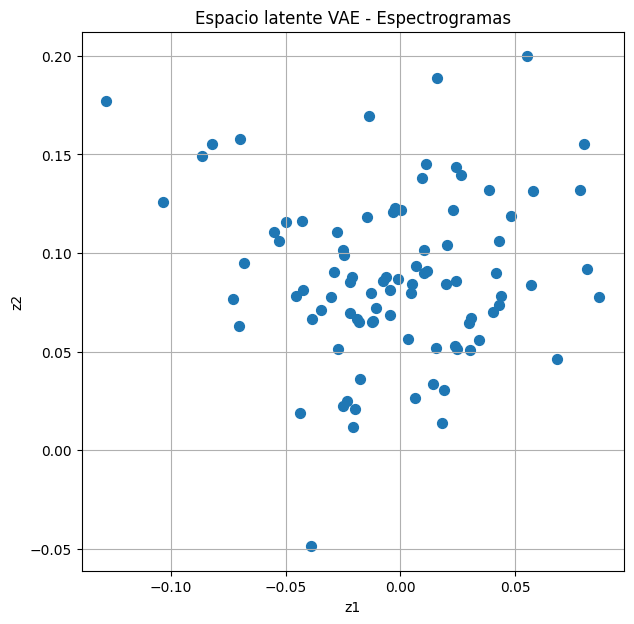

In [23]:
# ==========================================================
# CELDA 13 — VISUALIZAR EL ESPACIO LATENTE DEL VAE
# ==========================================================

# Obtenemos las coordenadas latentes de todos los sonidos.
# z_mean contiene la posición de cada sonido
# dentro del espacio latente.
z_mean, z_log_var = encoder.predict(
    X,
    verbose=0
)


# Creamos el gráfico del espacio latente.
plt.figure(
    figsize=(7, 7)
)


# Cada punto representa un sonido del dataset.
# La posición está determinada por sus coordenadas
# z1 y z2 aprendidas por el VAE.
plt.scatter(
    z_mean[:, 0],
    z_mean[:, 1],
    s=50
)


# Etiquetas de los ejes del espacio latente.
plt.xlabel("z1")
plt.ylabel("z2")


# Título del gráfico.
plt.title(
    "Espacio latente VAE - Espectrogramas"
)


# Añadimos una cuadrícula para facilitar
# la lectura de las posiciones.
plt.grid()

plt.show()


# Cada punto = un sonido.
# La posición de cada punto = representación aprendida por el VAE.
#
# z1 y z2 = las dos dimensiones del espacio latente.
#
# Este gráfico permite observar cómo se organiza
# el conjunto de sonidos dentro del espacio aprendido.

Resultado esperado:

Cada punto = un sonido del dataset.
Puntos cercanos = sonidos con estructura espectral parecida.
La distribución debería ser más continua que en el Autoencoder.

Después de esta celda viene lo más interesante:

Celda 14 — Explorar el espacio latente y generar espectrogramas nuevos

Ahí haremos:

(z1,z2)
    ↓
decoder
    ↓
nuevo espectrograma

y después veremos cómo volverlo sonido.

In [ ]:
# ==========================================================
# CELDA 14 — EXPLORAR EL ESPACIO LATENTE DEL VAE
# ==========================================================

# ipywidgets permite crear controles interactivos
# para movernos por el espacio latente.
from ipywidgets import interact

# Permite mostrar los elementos interactivos
# dentro del notebook.
from IPython.display import display

import matplotlib.pyplot as plt


# ----------------------------------------------------------
# CONTROLES DEL ESPACIO LATENTE
# ----------------------------------------------------------

# Creamos dos controles:
# z1 y z2 corresponden a las dos dimensiones
# del espacio latente.
@interact(
    z1=(-2.0, 2.0, 0.1),
    z2=(-2.0, 2.0, 0.1)
)


def explorar_latente(z1=0.0, z2=0.0):

    # Creamos un punto dentro del espacio latente.
    punto = np.array([
        [z1, z2]
    ])


    # ------------------------------------------------------
    # GENERAR ESPECTROGRAMA
    # ------------------------------------------------------

    # El Decoder recibe el punto elegido
    # y genera un nuevo espectrograma.
    generado = decoder.predict(
        punto,
        verbose=0
    )


    # Volvemos a dar al resultado la forma
    # original del espectrograma.
    generado = generado.reshape(
        257,
        87
    )


    # ------------------------------------------------------
    # VISUALIZAR
    # ------------------------------------------------------

    # Mostramos el espectrograma generado.
    plt.figure(
        figsize=(8, 4)
    )


    # Convertimos la amplitud a decibelios
    # para facilitar la visualización.
    librosa.display.specshow(
        librosa.amplitude_to_db(
            generado,
            ref=np.max
        ),
        sr=sr,
        hop_length=256,
        x_axis="time",
        y_axis="hz"
    )


    # Añadimos una escala de intensidad.
    plt.colorbar()


    # Mostramos las coordenadas del punto explorado.
    plt.title(
        f"Latente: z1={z1:.2f}, z2={z2:.2f}"
    )

    plt.show()


# Al mover z1 y z2:
#
# punto latente
#      ↓
# Decoder
#      ↓
# nuevo espectrograma
#
# Esto permite explorar diferentes regiones
# del espacio aprendido por el VAE.

interactive(children=(FloatSlider(value=0.0, description='z1', max=2.0, min=-2.0), FloatSlider(value=0.0, desc…

y cada movimiento hace que el decoder pregunte:

"¿Qué estructura espectral existe en esta zona del espacio aprendido?"

Todavía no suena porque falta:

espectrograma generado
        ↓
Griffin-Lim
        ↓
audio

Esa será la Celda 15. Ahí vamos a transformar lo que el VAE genera en algo audible.

Griffin-Lim intenta reconstruir la onda sonora a partir de la magnitud del espectrograma.

In [ ]:
# ==========================================================
# CELDA 15 — CONVERTIR ESPECTROGRAMA GENERADO A AUDIO
# ==========================================================

from IPython.display import Audio, display


# Función para escuchar el sonido correspondiente
# a un punto determinado del espacio latente.
def escuchar_latente(z1, z2):

    # Creamos el punto dentro del espacio latente.
    punto = np.array([
        [z1, z2]
    ])


    # El Decoder genera un nuevo espectrograma
    # a partir del punto elegido.
    generado = decoder.predict(
        punto,
        verbose=0
    )


    # Volvemos a convertir el resultado
    # en la matriz original del espectrograma.
    espectro = generado.reshape(
        257,
        87
    )


    # ------------------------------------------------------
    # RECONSTRUIR EL AUDIO
    # ------------------------------------------------------

    # Griffin-Lim estima la señal de audio
    # a partir del espectrograma generado.
    audio = librosa.griffinlim(
        espectro,
        hop_length=256,
        n_iter=32
    )


    # Normalizamos el audio para evitar
    # niveles de amplitud demasiado altos.
    audio = audio / np.max(
        np.abs(audio)
    )


    # Reproducimos el audio dentro de Colab.
    display(
        Audio(
            audio,
            rate=sr
        )
    )


# ==========================================================
# EJEMPLO
# ==========================================================

# Exploramos el punto (0, 0) del espacio latente.
escuchar_latente(
    0.0,
    0.0
)


# Flujo:
#
# punto (z1, z2)
#      ↓
# Decoder
#      ↓
# espectrograma generado
#      ↓
# Griffin-Lim
#      ↓
# audio

escuchar_latente(0.0,0.0)

Por eso escuchas, pero no puedes moverte ni ver dónde estás.

Ahora juntamos lo aprendido en la 14 (visualización) + la 15 (audio).

Celda 16 — Navegador latente visual + sonido

In [ ]:
# ==========================================================
# CELDA 16 — NAVEGAR EL ESPACIO LATENTE VAE CON SONIDO
# ==========================================================

from ipywidgets import interact
from IPython.display import display, Audio
import matplotlib.pyplot as plt


# ----------------------------------------------------------
# OBTENER LOS PUNTOS APRENDIDOS
# ----------------------------------------------------------

# Obtenemos la posición de cada sonido dentro
# del espacio latente aprendido por el Encoder.
z_mean, z_log_var = encoder.predict(
    X,
    verbose=0
)


# ----------------------------------------------------------
# CONTROLES DE NAVEGACIÓN
# ----------------------------------------------------------

# Creamos controles para desplazarnos
# entre diferentes posiciones del espacio latente.
@interact(
    z1=(-2.0, 2.0, 0.1),
    z2=(-2.0, 2.0, 0.1)
)


def navegar_VAE(z1=0.0, z2=0.0):

    # ======================================================
    # VISUALIZAR POSICIÓN
    # ======================================================

    # Mostramos todos los sonidos aprendidos
    # como puntos dentro del espacio latente.
    plt.figure(figsize=(5, 5))

    plt.scatter(
        z_mean[:, 0],
        z_mean[:, 1],
        s=50
    )


    # Marcamos la posición que estamos explorando.
    plt.scatter(
        z1,
        z2,
        s=200,
        marker="X"
    )


    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.title(
        "Navegación espacio latente VAE"
    )

    plt.grid()
    plt.show()


    # ======================================================
    # GENERAR ESPECTROGRAMA
    # ======================================================

    # Creamos el punto seleccionado
    # dentro del espacio latente.
    punto = np.array([
        [z1, z2]
    ])


    # El Decoder genera un nuevo espectrograma
    # correspondiente a esa posición.
    generado = decoder.predict(
        punto,
        verbose=0
    )


    # Recuperamos la forma original del espectrograma.
    espectro = generado.reshape(
        257,
        87
    )


    # ======================================================
    # CONVERTIR A AUDIO
    # ======================================================

    # Griffin-Lim reconstruye una señal de audio
    # a partir del espectrograma generado.
    audio = librosa.griffinlim(
        espectro,
        hop_length=256,
        n_iter=32
    )


    # Normalizamos la amplitud del audio.
    audio = audio / np.max(
        np.abs(audio)
    )


    # Reproducimos el sonido generado.
    display(
        Audio(
            audio,
            rate=sr
        )
    )


# Al mover z1 y z2:
#
# posición
#    ↓
# espacio latente
#    ↓
# Decoder
#    ↓
# espectrograma generado
#    ↓
# Griffin-Lim
#    ↓
# sonido
#
# Esta celda permite recorrer el espacio latente
# y escuchar los sonidos asociados a diferentes posiciones.

interactive(children=(FloatSlider(value=0.0, description='z1', max=2.0, min=-2.0), FloatSlider(value=0.0, desc…

# Limitación del experimento 004

En este experimento trabajamos con:

```text
90 sonidos
+
1 segundo de duración
+
sonidos sintéticos simples
+
pocas variaciones
```

Para una red neuronal, este conjunto de datos es relativamente pequeño.

La consecuencia esperable es:

```text
dataset pequeño
      ↓
VAE aprende una región limitada
      ↓
espacio latente poco variado
      ↓
poca diferencia entre posiciones cercanas
      ↓
sonidos similares
```

Es como enseñar a una máquina un mapa de una ciudad utilizando solamente unas pocas calles: puede aprender la estructura general, pero habrá pocos lugares interesantes para explorar.

---

# Siguiente experimento — Dataset sonoro más rico

Antes de cambiar el sistema de control, aumentamos la diversidad del material sonoro.

## 1. Más frecuencias

En lugar de trabajar solamente con:

```text
100 Hz — 1000 Hz
```

ampliamos el rango, por ejemplo:

```text
50 Hz — 4000 Hz
```

## 2. Más tipos de síntesis

Además de ondas sinusoidales:

```text
seno
cuadrada
sierra
FM
AM
ruido filtrado
granular simple
```

## 3. Más variaciones de parámetros

Cada sonido puede variar en:

```text
frecuencia
armónicos
envolvente
duración
ataque
decaimiento
modulación
```

De esta manera pasamos de:

```text
90 ejemplos
```

a un dataset del orden de:

```text
3000 — 10000 sonidos sintéticos
```

sin necesidad de descargar archivos de audio externos.

---

# La arquitectura se mantiene

El objetivo no es cambiar todavía la arquitectura del sistema, sino darle **más diversidad sonora para aprender**.

```text
dataset sonoro más grande
          ↓
         STFT
          ↓
         VAE
          ↓
    espacio latente 2D
          ↓
       navegación
          ↓
         audio
```

Con un dataset más diverso, esperamos observar una organización más rica del espacio latente.

Por ejemplo, podrían aparecer regiones relacionadas con características como:

```text
graves ←────────────→ agudos

suave ←─────────────→ complejo

armónico ←──────────→ ruidoso
```

Estas relaciones **no se programan explícitamente**.

El objetivo es observar qué organizaciones aparecen a partir de los datos que recibe el modelo.

---

# Cambio conceptual

El objetivo no es construir:

```text
gesto A → sonido A
gesto B → sonido B
gesto C → sonido C
```

sino avanzar hacia:

```text
gesto
  ↓
posición
  ↓
región del espacio latente
  ↓
características sonoras
  ↓
sonido
```

Por eso, antes de introducir el gesto físico, el siguiente paso es construir un **territorio sonoro suficientemente rico para que tenga sentido explorarlo**.
